# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [2]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    plot_raw,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [3]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)


## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run** (`plot_raw(g)`); **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
plot_raw(g)                   # raw view FIRST — rails/clipping, dead channels, streaks live here

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — Gate C: `gate-current-sanity-check` (cooldown liveness, first-session branch)

Each Keithley gate 0 → each committed card limit, other gate at 0, Si = 0 V, B = 0 T, I = 10 nA (1.0 V / 100 MΩ, 13.777 Hz), NPLC 10 on the gate-current channels, sr1 sens 1 mV, τ 0.1 s, 1 s dwell. No designated references (first session of this cooldown) — judged on its own terms: liveness, leakage, resistance scale.


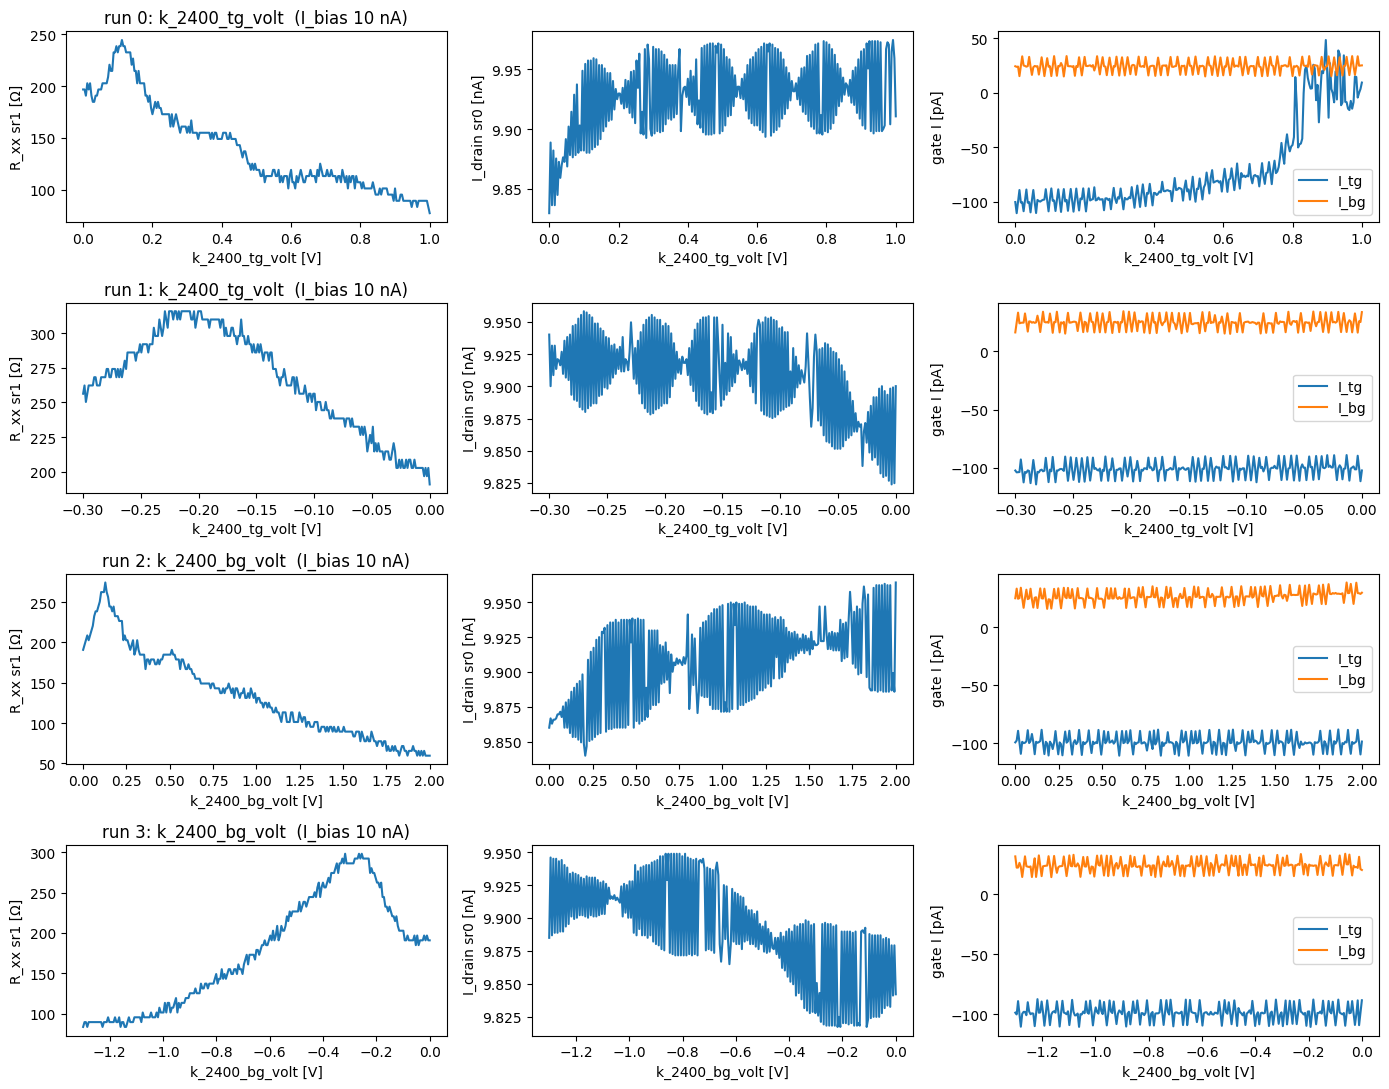

run 0 k_2400_tg_volt: R_xx 77..244 Ω, peak at +0.112 V | I_drain 9.83..9.97 nA | |I_tg|max 110 pA, |I_bg|max 34 pA | 2.04 s/pt (NPLC 10 + 1 s) | T 1.186-1.187 K
run 1 k_2400_tg_volt: R_xx 191..316 Ω, peak at -0.198 V | I_drain 9.82..9.96 nA | |I_tg|max 114 pA, |I_bg|max 34 pA | 2.04 s/pt (NPLC 10 + 1 s) | T 1.185-1.186 K
run 2 k_2400_bg_volt: R_xx 60..274 Ω, peak at +0.128 V | I_drain 9.84..9.96 nA | |I_tg|max 111 pA, |I_bg|max 39 pA | 2.06 s/pt (NPLC 10 + 1 s) | T 1.185-1.185 K
run 3 k_2400_bg_volt: R_xx 83..298 Ω, peak at -0.255 V | I_drain 9.82..9.95 nA | |I_tg|max 111 pA, |I_bg|max 34 pA | 2.06 s/pt (NPLC 10 + 1 s) | T 1.184-1.185 K
n at the R_xx maxima (geometry prior): TG-leg -0.35e12, BG-leg -0.38e12 cm^-2 -> n_offset ≈ +0.36e12 (to be replaced by the gatemap ridge fit)


In [6]:
# Gate C — gate-current-sanity-check, runs 0-3 (TG 0->+1, 0->-0.3; BG 0->+2, 0->-1.3 V; other gate 0, Si 0, B 0, 10 nA)
# Raw first: per leg, Rxx (sr1, unity gain, / I_bias), drain current (sr0 / gain), gate currents.
ids = [0, 1, 2, 3]
fig, axs = plt.subplots(len(ids), 3, figsize=(14, 11), squeeze=False)
summary = {}
for row, i in enumerate(ids):
    r = run(i)
    mc = r.meta["measurement_config"]
    gain = float(mc["sr0_gain"])
    ib = float(r.meta["instruments"]["sr1"]["snapshot"]["parameters"]["amplitude"]["value"]) / float(mc["bias_resistor"])
    x = r.col(r.swept_axis)
    rxx = r.col("sr1_X") / ib
    i0 = r.col("sr0_X") / gain
    itg, ibg = r.col("k_2400_tg_curr"), r.col("k_2400_bg_curr")
    summary[i] = dict(axis=r.swept_axis, vpk=float(x[np.argmax(rxx)]), rpk=float(rxx.max()), rmin=float(rxx.min()),
                      i0=(float(i0.min()), float(i0.max())), itg=float(np.abs(itg).max()), ibg=float(np.abs(ibg).max()),
                      dt=float(np.median(np.diff(r.col("time")))), T=(float(r.col("T_sample").min()), float(r.col("T_sample").max())))
    a = axs[row]
    a[0].plot(x, rxx); a[0].set_ylabel("R_xx sr1 [Ω]"); a[0].set_title(f"run {i}: {r.swept_axis}  (I_bias {ib*1e9:.0f} nA)")
    a[1].plot(x, i0 * 1e9); a[1].set_ylabel("I_drain sr0 [nA]")
    a[2].plot(x, itg * 1e12, label="I_tg"); a[2].plot(x, ibg * 1e12, label="I_bg"); a[2].set_ylabel("gate I [pA]"); a[2].legend()
    for ax in a: ax.set_xlabel(r.swept_axis + " [V]")
plt.tight_layout(); plt.show()
for i, d in summary.items():
    print(f"run {i} {d['axis']}: R_xx {d['rmin']:.0f}..{d['rpk']:.0f} Ω, peak at {d['vpk']:+.3f} V | I_drain {d['i0'][0]*1e9:.2f}..{d['i0'][1]*1e9:.2f} nA | "
          f"|I_tg|max {d['itg']*1e12:.0f} pA, |I_bg|max {d['ibg']*1e12:.0f} pA | {d['dt']:.2f} s/pt (NPLC 10 + 1 s) | T {d['T'][0]:.3f}-{d['T'][1]:.3f} K")
# CNP offset on the geometry prior from the two single-gate maxima (V_bg = 0 / V_tg = 0):
n_tg = cal.density(summary[1]["vpk"], 0.0); n_bg = cal.density(0.0, summary[3]["vpk"])
print(f"n at the R_xx maxima (geometry prior): TG-leg {n_tg*1e-16:+.2f}e12, BG-leg {n_bg*1e-16:+.2f}e12 cm^-2 -> n_offset ≈ {-(n_tg+n_bg)/2*1e-16:+.2f}e12 (to be replaced by the gatemap ridge fit)")


**Read (gate C verdict: PASS).** Device alive on the provided configuration: drain current 9.8–9.97 nA on every leg (the full bias reaches B_3), R_xx (B_1–B_2) 60–320 Ω, smooth and structured on all four legs. Gates clean to every card limit: |I_tg| ≤ 115 pA (a −100 pA offset that relaxes toward 0 above V_tg ≈ +0.8 V with wider noise, no turn-up), |I_bg| ≤ 40 pA — nothing near the 1 nA ceiling. T_sample 1.184–1.187 K throughout. Timing calibration: 2.05 s/pt at NPLC 10 + 1 s dwell → readback ≈ 1.05 s/pt at NPLC 10 (rig-card figure confirmed).

Features (geometry prior, uncalibrated): the R_xx maximum sits at V_tg = −0.22 V (V_bg = 0) and at V_bg = −0.25 V (V_tg = 0) — both ≈ −0.38 × 10¹² cm⁻² of gate density, i.e. one CNP ridge with n_offset ≈ +0.38 × 10¹² (electron-doped at zero gates). CNP contrast is weak (×1.6 over the metallic flanks) — recorded, not read as stacking (investigation: CNP magnitude is not a stacking read). A secondary R_xx peak ≈ 0.18 × 10¹² above the CNP on the electron side is present on both single-gate legs (run 0 at V_tg +0.10, run 2 at V_bg +0.12; opposite D signs) — a density feature to watch for in the gatemap. The hole flank flattens near ~85 Ω below V_bg ≈ −1.0 V (run 3). Readback quantization: sr1 at 1 mV sens steps at 60 nV (6 Ω) — the gatemap runs at 50 µV. Next: Step 1 gatemap over the full box (run 4).


## Run 4 — gatemap: full validator box at B = 0 (`gatemap` → `cnp-and-dline-calibration` steps 0–4)

TG −0.3…+1.0 V fast (66 pts, 20 mV) × BG −1.3…+2.0 V slow (67 rows, 50 mV), Si = 0, I = 10 nA, sr1 sens 50 µV, τ 0.1 s, dwell 0.7 s; 62 min wall (0.84 s/pt). Raw map first (left), then the ridge extraction + line fit (middle) and the (n, D) reprojection on the fitted ratio (right).


run 4: 67/67 rows complete, nfast=66, Vbg -1.300..+2.000, Vtg -0.300..+1.000
R_xx: 35.7..3014.8 Ohm | I_drain 9.77..9.98 nA
sr1 full scale 5000 Ohm; railed points: 0 (0.0%)
gate currents: |I_tg| max 222 pA, |I_bg| max 120 pA
ridge rows: 37 unclipped of 67; 37 with contrast >= 1.5; 26 kept after 2-sigma rejection (Vbg -1.25..+0.35)
CNP line (Vtg vs Vbg): Vtg = -0.7271 * Vbg + +0.0395 ; rms residual 17.7 mV ; ridge R at fit rows 1027 Ohm (median)
  => c_bg/c_tg = 0.7271 (geometry prior 0.8636 from 11 nm / 9.5 nm)
calibrated: c_tg 2.7961e-03 (prior), c_bg 2.0330e-03 (ratio-calibrated), n_offset -0.069e12 cm^-2; closure max|n| on ridge 0.000e12
ridge R along fitted CNP line (D [V/nm] : R [Ohm]): +0.30:2209, +0.27:2096, +0.24:2150, +0.20:1743, +0.17:1120, +0.13:733, +0.10:477, +0.06:354, +0.03:253, -0.01:234, -0.04:333, -0.07:474
ridge R minimum 208 Ohm at D = +0.006 V/nm (geometric D) -> candidate D_offset = -0.006 V/nm (so the gap minimum reads D = 0)
D = 0 line realized: n -1.11..+3.42 e

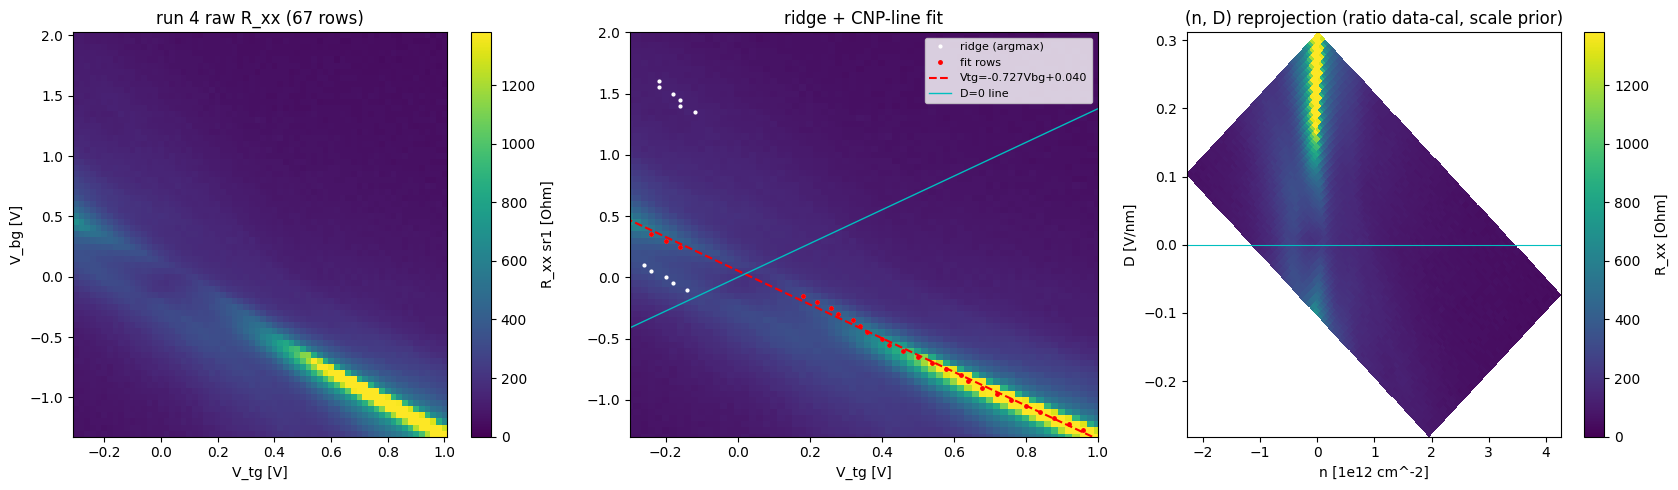

In [7]:
# Run 4 — gatemap, full validator box, B = 0, Si = 0, 10 nA. Re-form (TSV, complete rows), CNP ridge, CNP-line fit, R(D) profile, D-line realization.
"""Gatemap re-form + CNP-ridge extraction + CNP-line fit (cnp-and-dline-calibration steps 0-4).
Usage: menv python hera_scratch/gatemap_ana.py <run_id> [--fit-rows lo hi]
Works on partial data (complete rows only).
"""
import numpy as np
from pathlib import Path
from scipy.ndimage import gaussian_filter1d
from hera.analysis import open_run, fan_grids, resistance_grids, GateCalibration, luttinger_frequency
from sharpelab_nb.gates import calc_gate_voltages

rid = 4
r = run(rid)
f = fan_grids(r)
rg = resistance_grids(f)
Vbg = f.slow                          # (nrows,)
Vtg = f.grid("k_2400_tg_volt")[0]     # (nfast,)
R = np.abs(rg.R["sr1"])               # (nrows, nfast)
I = rg.current
print(f"run {rid}: {f.nrows}/{len(r.meta['slow_setpoints'])} rows complete, nfast={f.nfast}, Vbg {Vbg.min():+.3f}..{Vbg.max():+.3f}, Vtg {Vtg.min():+.3f}..{Vtg.max():+.3f}")
print(f"R_xx: {np.nanmin(R):.1f}..{np.nanmax(R):.1f} Ohm | I_drain {np.nanmin(I)*1e9:.2f}..{np.nanmax(I)*1e9:.2f} nA")
sens = r.meta["instruments"]["sr1"]["snapshot"]["parameters"]["sensitivity"]["value"]
ib = r.meta["instruments"]["sr1"]["snapshot"]["parameters"]["amplitude"]["value"] / r.meta["measurement_config"]["bias_resistor"]
rfs = sens / ib
railed = (R > 0.9 * rfs)
print(f"sr1 full scale {rfs:.0f} Ohm; railed points: {railed.sum()} ({100*railed.mean():.1f}%)")
itg, ibg = f.grid("k_2400_tg_curr"), f.grid("k_2400_bg_curr")
print(f"gate currents: |I_tg| max {np.abs(itg).max()*1e12:.0f} pA, |I_bg| max {np.abs(ibg).max()*1e12:.0f} pA")

# --- ridge extraction per row (smoothed argmax, edge-clip guard, contrast guard, continuity) ---
Rs = gaussian_filter1d(R, sigma=1.5, axis=1)
idx = np.argmax(Rs, axis=1)
edge = (idx <= 1) | (idx >= f.nfast - 2)
vtg_ridge = Vtg[idx]
contrast = Rs[np.arange(f.nrows), idx] / np.median(Rs, axis=1)
CONTRAST_MIN = 1.5   # heuristic: rows whose peak is < 1.5x the row median have no locatable ridge (weak-gap D~0 rows)
rows_ok = ~edge & (contrast >= CONTRAST_MIN)
# seed the line on the highest-contrast rows (the strong, in-box part of the ridge), then accept rows near it:
# a parallel/secondary feature (or a ridge that has left the box) has no vote.
seed = np.zeros(f.nrows, bool); seed[np.argsort(-np.where(rows_ok, contrast, 0))[:12]] = True
p = np.polyfit(Vbg[seed], vtg_ridge[seed], 1)
sel = rows_ok & (np.abs(vtg_ridge - np.polyval(p, Vbg)) < 0.08)
for _ in range(5):
    p = np.polyfit(Vbg[sel], vtg_ridge[sel], 1)
    res = vtg_ridge - np.polyval(p, Vbg)
    sig = max(np.std(res[sel]), 0.01)
    new = rows_ok & (np.abs(res) < 2.5 * sig)
    if np.all(new == sel): break
    sel = new
p = np.polyfit(Vbg[sel], vtg_ridge[sel], 1)
res = vtg_ridge[sel] - np.polyval(p, Vbg[sel])
slope, b = p
print(f"ridge rows: {(~edge).sum()} unclipped of {f.nrows}; {rows_ok.sum()} with contrast >= {CONTRAST_MIN}; {sel.sum()} kept after 2-sigma rejection (Vbg {Vbg[sel].min():+.2f}..{Vbg[sel].max():+.2f})")
print(f"CNP line (Vtg vs Vbg): Vtg = {slope:+.4f} * Vbg + {b:+.4f} ; rms residual {np.std(res)*1e3:.1f} mV ; ridge R at fit rows {np.median(R[np.arange(f.nrows)[sel], idx[sel]]):.0f} Ohm (median)")
print(f"  => c_bg/c_tg = {-slope:.4f} (geometry prior 0.8636 from 11 nm / 9.5 nm)")

# --- calibration: anchor c_tg at the stack prior, c_bg from the ratio; n_offset from the intercept ---
cal0 = GateCalibration.from_thicknesses(9.5e-9, 11e-9, 0)
c_tg = cal0.c_tg; c_bg = -slope * c_tg
n_off = -GateCalibration(c_tg, c_bg).density(b, 0.0)
cal = GateCalibration(c_tg, c_bg, n_offset=float(n_off))
n_chk = cal.density(np.polyval(p, Vbg[sel]), Vbg[sel])
print(f"calibrated: c_tg {c_tg:.4e} (prior), c_bg {c_bg:.4e} (ratio-calibrated), n_offset {n_off*1e-16:+.3f}e12 cm^-2; closure max|n| on ridge {np.abs(n_chk).max()*1e-16:.3f}e12")

# --- ridge R(D) along the fitted line: the gap minimum locates D = 0 physically (cnp-and-dline step 3, D offset) ---
vtg_line = np.polyval(p, Vbg)
R_line = np.array([np.interp(vtg_line[i], Vtg, Rs[i]) for i in range(f.nrows)])
inbox = (vtg_line >= Vtg.min()) & (vtg_line <= Vtg.max())
_, D_line = cal.n_D(vtg_line, Vbg)
D_line = D_line / 1e9
k = np.argmin(R_line[inbox]); D_min = D_line[inbox][k]
print("ridge R along fitted CNP line (D [V/nm] : R [Ohm]):", ", ".join(f"{d:+.2f}:{rr:.0f}" for d, rr in zip(D_line[inbox][::3], R_line[inbox][::3])))
print(f"ridge R minimum {R_line[inbox][k]:.0f} Ohm at D = {D_min:+.3f} V/nm (geometric D) -> candidate D_offset = {-D_min:+.3f} V/nm (so the gap minimum reads D = 0)")

# --- D = 0 line design, clipped to validators by dropping (sharpelab_nb.gates units: 1e12 cm^-2, V/nm) ---
TG = (-0.3, 1.0); BG = (-1.3, 2.0)
n_off12 = float(n_off) * 1e-16
ns = np.linspace(-3.0, 5.0, 801)
def realized(D0):
    vt_, vb_ = calc_gate_voltages(ns, D0 * np.ones_like(ns), c_tg, c_bg, n_offset=n_off12, D_offset=0.0)
    ok_ = (vt_ >= TG[0]) & (vt_ <= TG[1]) & (vb_ >= BG[0]) & (vb_ <= BG[1])
    return vt_, vb_, ok_
vt, vb, ok = realized(0.0)
if ok.any():
    print(f"D = 0 line realized: n {ns[ok].min():+.2f}..{ns[ok].max():+.2f} e12 cm^-2 (F_L {luttinger_frequency(ns[ok].min()*1e16):.1f} / {luttinger_frequency(ns[ok].max()*1e16):.1f} T); Vtg {vt[ok].min():+.3f}..{vt[ok].max():+.3f}, Vbg {vb[ok].min():+.3f}..{vb[ok].max():+.3f}")
for D0 in (0.05, -0.05, 0.1, -0.1, 0.2, -0.2):
    vt2, vb2, ok2 = realized(D0)
    if ok2.any(): print(f"D = {D0:+.2f} V/nm realized: n {ns[ok2].min():+.2f}..{ns[ok2].max():+.2f} e12")

# --- plots: raw map, ridge + fit overlay, (n, D) reprojection ---
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
ax = axs[0]
pc = ax.pcolormesh(Vtg, Vbg, R, shading="nearest", cmap="viridis", vmin=0, vmax=np.nanpercentile(R, 99))
plt.colorbar(pc, ax=ax, label="R_xx sr1 [Ohm]"); ax.set_xlabel("V_tg [V]"); ax.set_ylabel("V_bg [V]"); ax.set_title(f"run {rid} raw R_xx ({f.nrows} rows)")
ax = axs[1]
pc = ax.pcolormesh(Vtg, Vbg, R, shading="nearest", cmap="viridis", vmin=0, vmax=np.nanpercentile(R, 99))
ax.plot(vtg_ridge[rows_ok], Vbg[rows_ok], "w.", ms=4, label="ridge (argmax)")
ax.plot(vtg_ridge[sel], Vbg[sel], "r.", ms=5, label="fit rows")
xx = np.array(BG); ax.plot(np.polyval(p, xx), xx, "r--", label=f"Vtg={slope:+.3f}Vbg{b:+.3f}")
ax.plot(vt[ok], vb[ok], "c-", lw=1, label="D=0 line")
ax.set_xlim(TG); ax.set_ylim(BG); ax.legend(fontsize=8, loc="upper right"); ax.set_xlabel("V_tg [V]"); ax.set_title("ridge + CNP-line fit")
ax = axs[2]
VT, VB = np.meshgrid(Vtg, Vbg)
n2, D2 = cal.n_D(VT, VB)
pc = ax.pcolormesh(n2*1e-16, D2/1e9, R, shading="nearest", cmap="viridis", vmin=0, vmax=np.nanpercentile(R, 99))
plt.colorbar(pc, ax=ax, label="R_xx [Ohm]"); ax.axhline(0, color="c", lw=0.8); ax.set_xlabel("n [1e12 cm^-2]"); ax.set_ylabel("D [V/nm]"); ax.set_title("(n, D) reprojection (ratio data-cal, scale prior)")
plt.tight_layout()
plt.show()


**Read.** One strong charge-neutrality ridge crosses the box from (V_tg +1.0, V_bg −1.3) to about (+0.2, −0.2), gapping steeply with positive D: R_xx ≈ 3 kΩ at D ≈ +0.3 V/nm, 1.1 kΩ at +0.17, 470 Ω at +0.10, ~210–250 Ω near D ≈ 0 (the ridge is then barely above the metallic flanks) and rising again on the D < 0 side within the little the box reaches (330 Ω at −0.04, 470 at −0.07). No railing (5 kΩ full scale), gate currents at the NPLC-1 noise floor (|I| ≤ 220 pA), T 1.185 K.

**CNP-line fit** (axis orientation: ridge position = V_tg, fitted against V_bg rows; rows V_bg −1.25…−0.2 where the ridge has contrast ≥ 1.5 and sits inside the box — seeded on the 12 strongest rows, 2.5σ rejection): V_tg = −0.727·V_bg + 0.040, rms residual 18 mV ⇒ **c_bg/c_tg = 0.727 (data-calibrated)** vs the geometry prior 0.864 (11 nm / 9.5 nm) — a 16 % disagreement. The ridge is mildly curved (local slope ≈ −0.8 at D ≈ +0.3, ≈ −0.65 near D ≈ +0.05), so the ratio is window-dependent at the ±10 % level; this fit spans the operating window the campaign uses (D ≲ 0.2). Anchor: c_tg at the stack prior (single 9.5 nm hBN), c_bg from the ratio; n_offset = −0.07 × 10¹² cm⁻² (intercept); **absolute scale: geometry prior until SdH/QH pins it** (the 16 % could equally be a TG-thickness error — the Luttinger sum will tell). D_offset = 0 taken at the ridge-R minimum, which falls at geometric D = +0.006 V/nm — i.e. the gap minimum locates D = 0 where the geometry puts it; stated, not assumed.

**Second feature — not the channel CNP.** A weaker R_xx maximum (≈ 300 Ω) runs nearly vertically at V_tg ≈ −0.2…−0.3 V for V_bg ≳ 0, independent of V_bg: a region of the B_1–B_2 path gated by the top gate only (outside the graphite back gate's footprint), hitting its own CNP at V_tg ≈ −0.2. This is what the single-gate gate-C scans found (runs 1/3 maxima at V_tg −0.20 / V_bg −0.25 sit on it, not on the dual-gated line) — the gate-C n_offset ≈ +0.36 × 10¹² was this region's doping, superseded. Consequences: (i) the hole side of the D = 0 line (V_tg → −0.3) drives this series region to neutrality — hole-side SdH on this pair will be confounded/attenuated; (ii) on the electron side the region is metallic (n′ ≈ c_tg·(V_tg + 0.2), ≈ +1.8 × 10¹² at the design point) and can contribute SdH tones that track V_tg only, not the dual-gated n — a confound to screen in the fan (a tone that does not follow the D = 0 n-line is this region). Si (contact-doping gate, ±25 V available) is the knob that could push it away if it turns out to be contact-adjacent — not used yet.

**D = 0 line (realized, clipped by dropping):** n = −1.11 … +3.42 × 10¹² cm⁻² (F_L 11.5 / 35.4 T), V_tg −0.30…+1.00, V_bg −0.41…+1.38. Hole side at D = 0 stays in the low-|n| exception regime (and runs into the series feature); the electron side reaches the design densities (|n| ≳ 2–3 × 10¹²). Next: Step 3 electron spot check at n = +3.0 × 10¹², D = 0.


## Run 5 — SdH spot check, electron side, D = 0, n_design = +3.0 × 10¹² (`sdh-spot-check`)

(V_tg, V_bg) = (+0.879, +1.209) V, Si = 0, B 0 → 10 T uniform 24 mT (417 pts, 14.3 s/pt: 73 min traverse + settle/dwell), I = 10 nA, sr1 autoranged, τ 0.1 s, dwell 0.7 s. Raw R(B) first (note: the B_1–B_2 signal goes negative near 2–4 T and climbs in a staircase to 600 Ω by 10 T — a Hall admixture R_xx + α·R_xy on this pair, α ~ 0.2; the oscillatory content is what the FFT reads), then `sdh_onset`, the background-subtracted 1/B trace, and the FFT stability sweep.


run 5: 417 pts, B 0.000..9.984 T, complete=True interrupted=False
R_xx: -17.3..590.4 Ohm (B=0: 52.2); I_drain 9.81..9.98 nA; T 1.181..1.304 K
F_L(n=+3.00e12) = 31.0 T
sdh_onset: onset_b = 2.37 T (tone 21.2 T) over B [0.31, 9.98] T
  tone   21.2 T: onset  2.37 T  dF  3.11 T  snr_max   26.5  [~6x3.5T]
  tone   29.1 T: onset  2.79 T  dF  3.87 T  snr_max   21.8  [~5x6.0T]
  tone    9.8 T: onset  2.32 T  dF  3.02 T  snr_max    8.0  [marginal]
  tone    9.9 T: onset  0.31 T  dF  0.32 T  snr_max    5.3  [censored@edge, marginal]
  tone    6.0 T: UNTRACKED — never above threshold (max SNR 4.1 vs 5 across 7 windows)
  tone    3.5 T: UNTRACKED — never above threshold (max SNR 1.6 vs 5 across 3 windows)
  tone    7.6 T: UNTRACKED — never above threshold (max SNR 3.9 vs 5 across 7 windows)
  tone    4.4 T: UNTRACKED — never above threshold (max SNR 1.2 vs 5 across 5 windows)
FFT B≥2.37 T deg 5: top peaks (T, rel): 6.2 (1.00), 28.1 (0.67), 21.8 (0.60), 15.6 (0.55), 37.4 (0.15), 187.0 (0.13)
FFT B≥2

C:\Users\DGG\AppData\Local\Temp\ipykernel_22296\2340541121.py:29: UserWarning: sdh_onset: untracked tone(s): 6.0 T (never above threshold (max SNR 4.1 vs 5 across 7 windows)); 3.5 T (never above threshold (max SNR 1.6 vs 5 across 3 windows)); 7.6 T (never above threshold (max SNR 3.9 vs 5 across 7 windows)); 4.4 T (never above threshold (max SNR 1.2 vs 5 across 5 windows))
  on = sdh_onset(R[m], B[m], b_lo=0.3)
C:\Users\DGG\AppData\Local\Temp\ipykernel_22296\2340541121.py:29: UserWarning: sdh_onset: marginal tone 9.9 T would carry the onset (0.31 T) — excluded; onset_b = 2.37 T from the 21.2 T tone
  on = sdh_onset(R[m], B[m], b_lo=0.3)


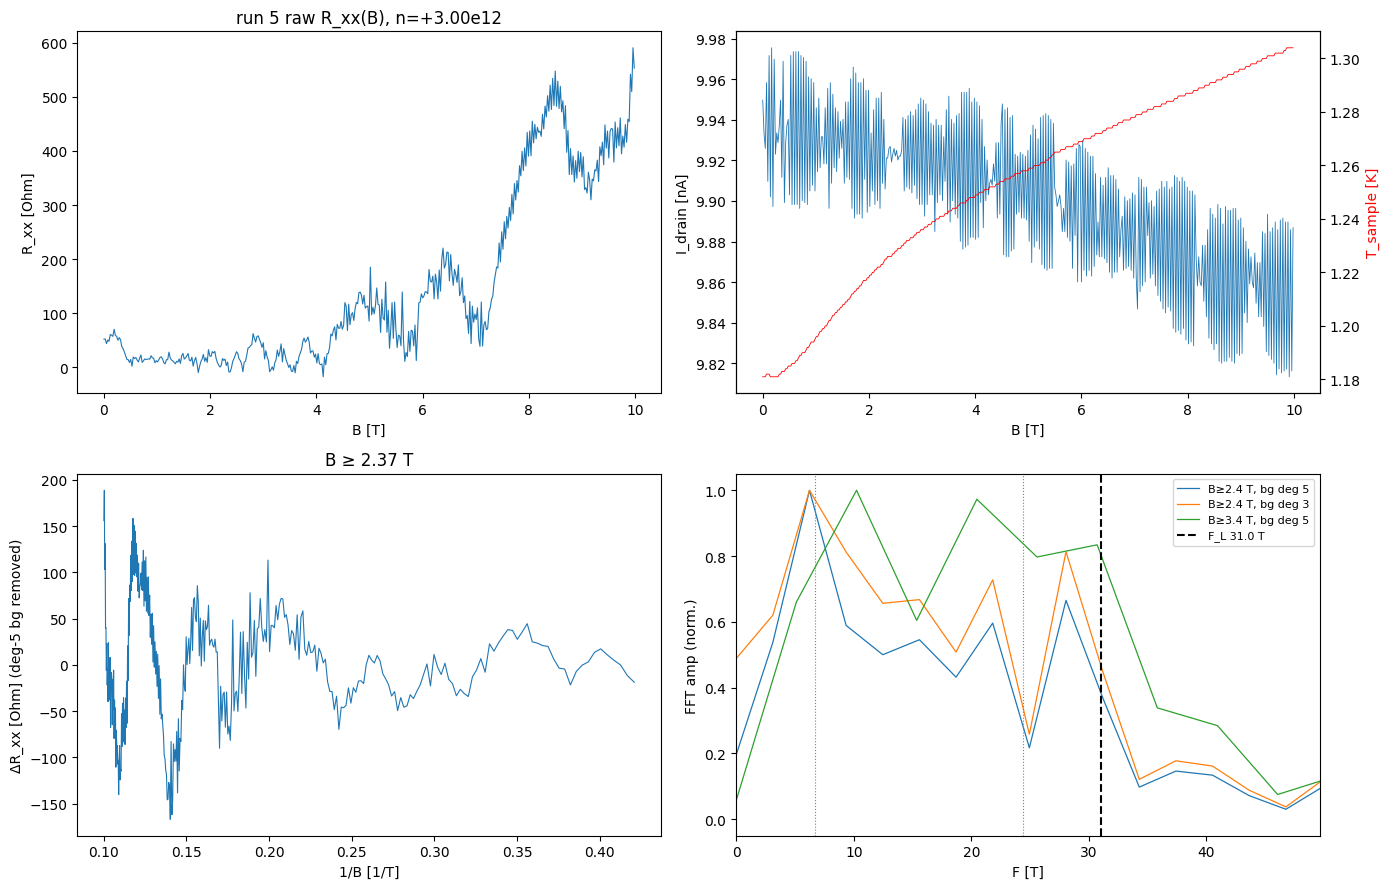

f1 + f2 = 28.0 T (observed sum tone 28.1 T); scale = (f1+f2)/F_L = 0.903 -> n = 2.71e12; partition 0.779 / 0.221; f2 - f1 = 15.6 T (observed 15.6)


In [8]:
# Run 5 — sdh-spot-check, electron (n, D) = (+3.0e12, 0) design point, B 0 -> 10 T uniform 24 mT, 10 nA, sr1 autorange.
"""SdH spot-check read: raw R(B), onset (sdh_onset), FFT in 1/B (sdh_fft) vs F_L and the model tones.
Usage: menv python hera_scratch/spot_ana.py <run_id> <n_e12> [cutoff_T]
"""
import warnings
import numpy as np
from pathlib import Path
from hera.analysis import open_run, sdh_onset, sdh_fft, SdhOnsetError, luttinger_frequency

rid, n12, cutoff = 5, 3.0, None
r = run(rid)
mc = r.meta["measurement_config"]
ib = r.meta["instruments"]["sr1"]["snapshot"]["parameters"]["amplitude"]["value"] / mc["bias_resistor"]
B = r.col("magnet_field"); I = r.col("sr0_X") / float(mc["sr0_gain"]); R = r.col("sr1_X") / I
T = r.col("T_sample")
print(f"run {rid}: {r.rows} pts, B {B.min():.3f}..{B.max():.3f} T, complete={r.complete} interrupted={r.interrupted}")
print(f"R_xx: {R.min():.1f}..{R.max():.1f} Ohm (B=0: {R[np.argmin(np.abs(B))]:.1f}); I_drain {I.min()*1e9:.2f}..{I.max()*1e9:.2f} nA; T {T.min():.3f}..{T.max():.3f} K")
FL = luttinger_frequency(n12 * 1e16)
print(f"F_L(n={n12:+.2f}e12) = {FL:.1f} T")

fig, axs = plt.subplots(2, 2, figsize=(14, 9))
ax = axs[0, 0]; ax.plot(B, R, lw=0.8); ax.set_xlabel("B [T]"); ax.set_ylabel("R_xx [Ohm]"); ax.set_title(f"run {rid} raw R_xx(B), n={n12:+.2f}e12")
ax = axs[0, 1]; ax.plot(B, I * 1e9, lw=0.6); ax.set_xlabel("B [T]"); ax.set_ylabel("I_drain [nA]")
ax2 = ax.twinx(); ax2.plot(B, T, "r", lw=0.6); ax2.set_ylabel("T_sample [K]", color="r")

# onset
m = B > 0.2
try:
    on = sdh_onset(R[m], B[m], b_lo=0.3)
    print(on.summary())
    b_on = on.onset_b
except SdhOnsetError as ex:
    print("SdhOnsetError:", ex); on = None; b_on = None

# background-subtracted trace (degree-5 poly in B) for the eye
lo = cutoff if cutoff else (max(b_on, 1.0) if b_on else 1.5)
sel = (B >= lo)
pbg = np.polyfit(B[sel], R[sel], 5); dR = R[sel] - np.polyval(pbg, B[sel])
ax = axs[1, 0]; ax.plot(1 / B[sel], dR, lw=0.8); ax.set_xlabel("1/B [1/T]"); ax.set_ylabel("ΔR_xx [Ohm] (deg-5 bg removed)"); ax.set_title(f"B ≥ {lo:.2f} T")

# FFT vs 1/B, a few windows for the stability sweep
ax = axs[1, 1]
for blo_w, deg in ((lo, 5), (lo, 3), (min(lo + 1.0, B.max() - 2), 5)):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        freqs, spec = sdh_fft(R[:, None], B, b_range=(blo_w, B.max()), bg_degree=deg, nfft=4096, log=False)
    sp = spec[0]; ax.plot(freqs, sp / sp[freqs > 2].max(), lw=0.9, label=f"B≥{blo_w:.1f} T, bg deg {deg}")
    pk = [(freqs[i], sp[i]) for i in range(2, len(sp) - 2) if sp[i] > sp[i-1] and sp[i] > sp[i+1] and freqs[i] > 1.0]
    pk = sorted(pk, key=lambda t: -t[1])[:6]
    print(f"FFT B≥{blo_w:.2f} T deg {deg}: top peaks (T, rel): " + ", ".join(f"{f0:.1f} ({a/sp[freqs>2].max():.2f})" for f0, a in pk))
ax.axvline(FL, color="k", ls="--", label=f"F_L {FL:.1f} T")
for f0, lab in ((0.216 * FL, "ABAB light"), (0.787 * FL, "ABAB heavy")):
    ax.axvline(f0, color="gray", ls=":", lw=0.8)
ax.set_xlim(0, 1.6 * FL); ax.set_xlabel("F [T]"); ax.set_ylabel("FFT amp (norm.)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Luttinger / template read on the two fundamentals (B >= onset, deg-5 window):
f1, f2 = 6.2, 21.8
print(f"f1 + f2 = {f1+f2:.1f} T (observed sum tone 28.1 T); scale = (f1+f2)/F_L = {(f1+f2)/FL:.3f} -> n = {(f1+f2)/10.34:.2f}e12; partition {f2/(f1+f2):.3f} / {f1/(f1+f2):.3f}; f2 - f1 = {f2-f1:.1f} T (observed 15.6)")


**Read.** Oscillations are clean from **onset 2.4 T** (`sdh_onset`, carried by the 21-T tone; the 9.8-T track is marginal). Record above onset: 1/B = 0.10…0.42 T⁻¹ → δF = 3.1 T. FFT (B ≥ 2.37 T, bg deg 5 / deg 3 agree): **6.2 T (1.00), 21.8 T (0.60), 28.1 T (0.67), 15.6 T (0.55)**, 37.4 T (0.15); the B ≥ 3.4 T window gives 10.2 / 20.5 / 30.7 (coarser δF = 5 T, peaks merge) — the 6.2 and ~21–22 and ~28–31 groups are stable across windows, 15.6 and 10.2 are window-dependent (fork, not refined here).

Template (investigation Why / Verify): the two fundamentals **sum to 28.0 T = observed 28.1 T** and their difference **15.6 T = observed 15.6 T** — a {f₁, f₂, f₂+f₁, f₂−f₁} set, i.e. two Fermi surfaces in one region with inter-pocket magnetic breakdown / intermodulation (series regions cannot produce mixing products, so the pair is not a two-region artifact). Luttinger: f₁ + f₂ = 28.0 T ⇒ global scale 0.90 (n = 2.71 × 10¹² vs 3.0 designed; inside the 0.8–1.2 lever-arm band — the 16 % CNP-slope disagreement with geometry was a scale warning, now pinned at this density). Partition **0.78 / 0.22** — the ABAB model at n ≈ 2.7 × 10¹² (electron) gives 0.79 / 0.21 (20.7/25.8 at 2.5, 24.4/31.0 at 3.0); the ABCA template (one tone at F_L, no fundamentals below it) is **not** what is seen — the sub-F_L fundamentals are the strongest peaks. Trilayer ML+BL (adjacent-N) at this density would partition ≈ 0.12–0.15 / 0.85; 0.22 sits on the ABAB side but the investigation is explicit that the partition magnitude alone cannot decide — the F(n) trajectory (Step 4/5) does. **Lean at this single density: ABAB (pair + symmetry-allowed breakdown sum at F_L) — consistent-with, pending the fan.** Confound to carry: a TG-only series segment (run 4) would contribute a tone tracking V_tg (≈ 5.2·n + 4 T along D = 0 on the prior, ≈ 19.5 T here) — the 21.8 T tone is within δF of that; the mixing products argue against it, and the fan separates the two trajectories (9.3·n·{0.78, 0.22} vs 5.2·n + 4). High-field QH: a deep minimum at 7.3 T = ν ≈ 16 on the pinned scale (4L-consistent ladder member), but the Hall admixture makes the ν ≤ 12 minima unreadable on this pair — weak at most.

Handed to the fan: onset 2.4 T (B_lo; censored? no — the carrier tone dies into the floor at 2.37 T, measured), Δ(1/B) = 1/(3·F_L) held, fixed scale (see the fan cell), the electron side.


## Runs 6–7 — Si-gate test of the TG-only series segment: two TG linecuts at B = 10 T, V_bg = 0 (`gatemap` 1D cut)

Si = 0 (run 6, V_tg +1.0 → −0.3) and Si = +25 V (run 7, −0.3 → +1.0), 66 pts, 10 nA, sr1 autoranged; Si returned to 0 afterwards. Question: does Si move the V_bg-independent R_xx maximum at V_tg ≈ −0.2 V (run 4)?


run 6 Si = 0: |R| at Vtg -0.3/-0.2/-0.1/0.0/+0.1/+0.3/+0.6/+1.0 V = 1714 / 4468 / 14718 / 41774 / 29297 / 1319 / 293 / 830 Ohm
run 7 Si = +25 V: |R| at Vtg -0.3/-0.2/-0.1/0.0/+0.1/+0.3/+0.6/+1.0 V = 1700 / 4351 / 14003 / 1033761 / 188475 / 2015 / 307 / 27 Ohm


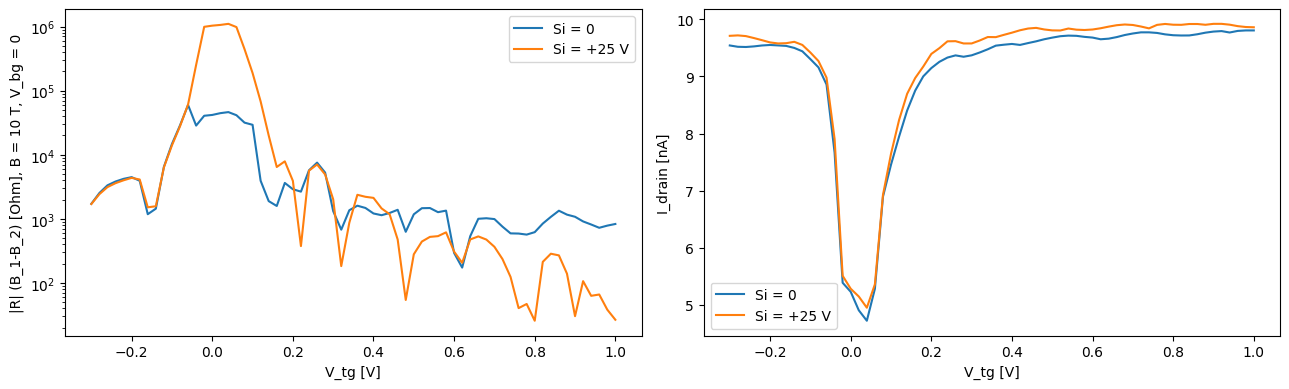

In [9]:
# Runs 6-7: TG linecuts at 10 T, Vbg = 0, Si = 0 vs +25 V. Raw R(Vtg) and drain current.
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for rid, lab in ((6, "Si = 0"), (7, "Si = +25 V")):
    r = run(rid); mc = r.meta["measurement_config"]
    I = r.col("sr0_X") / float(mc["sr0_gain"]); R = r.col("sr1_X") / I; x = r.col("k_2400_tg_volt"); o = np.argsort(x)
    ax[0].semilogy(x[o], np.abs(R[o]), label=lab); ax[1].plot(x[o], I[o] * 1e9, label=lab)
    print(f"run {rid} {lab}: |R| at Vtg -0.3/-0.2/-0.1/0.0/+0.1/+0.3/+0.6/+1.0 V = " + " / ".join(f"{abs(R[np.argmin(abs(x-v))]):.0f}" for v in (-0.3, -0.2, -0.1, 0.0, 0.1, 0.3, 0.6, 1.0)) + " Ohm")
ax[0].set_xlabel("V_tg [V]"); ax[0].set_ylabel("|R| (B_1-B_2) [Ohm], B = 10 T, V_bg = 0"); ax[0].legend()
ax[1].set_xlabel("V_tg [V]"); ax[1].set_ylabel("I_drain [nA]"); ax[1].legend(); plt.tight_layout(); plt.show()


**Read.** The V_tg ≈ −0.2 V feature is **Si-insensitive**: R(V_tg) for V_tg ≤ −0.1 V is identical at Si = 0 and +25 V (1.7 / 4.4 / 14 kΩ at −0.3 / −0.2 / −0.1 V in both runs). Si acts elsewhere: at the dual-gated CNP (V_tg ≈ 0, a ν = 0 insulator at 10 T) R climbs from 42 kΩ to ~1 MΩ and the drain current sags to ~5 nA, and at the high-n end R drops 830 → 27 Ω — the contact regions are Si-doped, the series segment is not. Consequence: the hole-side confound on the B_1–B_2 pair cannot be removed with the Si gate; Si stays at 0 for the rest of the session and the hole side is reported as geometry-limited on this pair. (The ν = 0 resistance at D = 0 is not a stacking read — survey §5.)


## Run 8 — Landau fan, electron side, D = 0 (`landau-fan-vti`): B 10 → 2.4 T uniform in 1/B (36 rows, Δ(1/B) = 0.0090) × n 3.4 → 1.5 × 10¹² design frame (41 pts; ×0.90–0.93 actual)

(V_tg, V_bg) line 0.45…1.00 / 0.42…1.38 V, Si = 0, I = 10 nA, sr1 50 µV fixed, τ 0.1 s, dwell 0.7 s; 80 min (0.81 s/pt + 55 min traverse). Raw (n, B) map first, then the per-column FFT with F_L and the ABAB / trilayer-ABA model curves and the series-segment line overlaid (scale 0.90 applied to n), then the peak table per column.


run 8: 36/36 rows, nfast 41; B 2.40..10.00 T; n_design 1.50..3.40 (x0.9 actual)
R: -134..1558 Ohm; I 9.81..9.96 nA; T 1.225..1.305 K
railed (>0.9 x 5 kOhm): 0 pts
column peaks (n_act : F [T] (rel amp) ...):
  n=+3.06: 6.9 (1.00), 33.1 (0.98), 16.6 (0.66), 25.2 (0.54)   F_L=31.6
  n=+2.97: 6.8 (1.00), 31.5 (0.68), 15.9 (0.58), 24.3 (0.54), 47.8 (0.35)   F_L=30.8
  n=+2.89: 7.1 (1.00), 31.1 (0.76), 14.5 (0.61), 22.0 (0.49), 40.9 (0.26)   F_L=29.9
  n=+2.80: 6.9 (1.00), 30.1 (0.74), 13.5 (0.68), 22.4 (0.58), 46.1 (0.26)   F_L=29.0
  n=+2.72: 6.6 (1.00), 13.4 (0.57), 28.7 (0.57), 21.7 (0.44), 49.6 (0.36)   F_L=28.1
  n=+2.63: 6.5 (1.00), 20.8 (0.67), 12.5 (0.62), 28.4 (0.55)   F_L=27.2
  n=+2.55: 6.1 (1.00), 27.1 (0.82), 12.6 (0.53)   F_L=26.3
  n=+2.46: 26.8 (1.00), 7.4 (0.73), 18.4 (0.59)   F_L=25.4
  n=+2.38: 26.3 (1.00), 4.3 (0.40), 19.2 (0.30), 12.9 (0.29)   F_L=24.6
  n=+2.29: 25.5 (1.00), 4.3 (0.64), 18.9 (0.55), 50.4 (0.32)   F_L=23.7
  n=+2.21: 24.2 (1.00), 13.9 (0.56), 46.5 (0.53

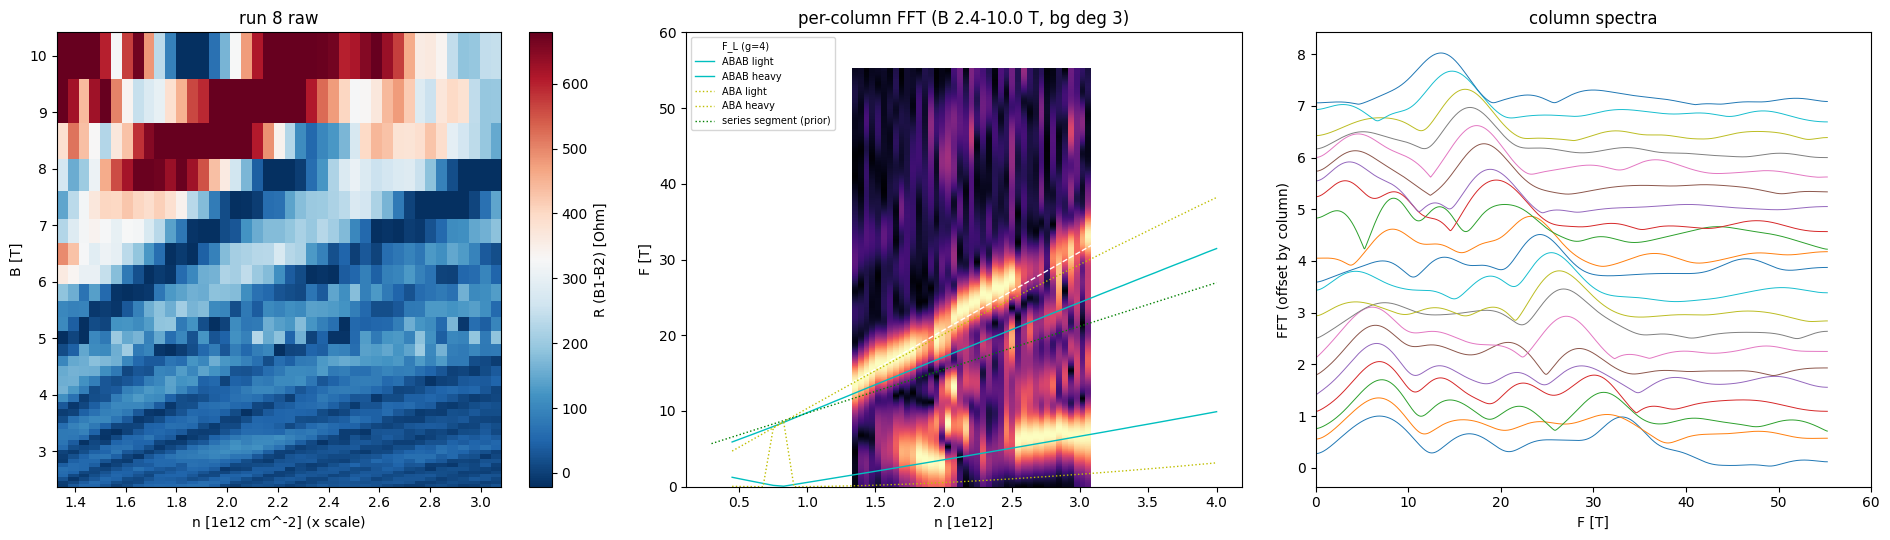

In [12]:
# Run 8 — landau-fan-vti, electron, D = 0: B 10 -> 2.4 T uniform 1/B (36 rows) x n 3.4 -> 1.5e12 design (41 pts). Raw map, per-column FFT, F(n) vs F_L + model overlays.
"""Landau fan read: raw map, per-column FFT in 1/B, F(n) peak set vs F_L and the model curves.
Usage: menv python hera_scratch/fan_ana.py <run_id> [scale]
"""
import warnings
import numpy as np
from pathlib import Path
from hera.analysis import open_run, fan_grids, resistance_grids, sdh_fft, luttinger_frequency
import importlib.util
def _load(name, rel):
    spec = importlib.util.spec_from_file_location(name, Path.home() / "measurement_env/hera/models" / rel / "fs_count_b0.py")
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod); return mod

rid, scale = 8, 0.90
C_TG, C_BG, N_OFF = 2.7961e-3, 2.0330e-3, -0.069
r = run(rid); f = fan_grids(r); rg = resistance_grids(f)
B = f.slow; R = rg.R["sr1"]; Vtg = f.grid("k_2400_tg_volt")[0]; Vbg = f.grid("k_2400_bg_volt")[0]
e = 1.602176634e-19
n_design = (C_TG * Vtg + C_BG * Vbg) / e * 1e-16 + N_OFF          # design frame, 1e12
n_act = scale * n_design
print(f"run {rid}: {f.nrows}/{len(r.meta['slow_setpoints'][0])} rows, nfast {f.nfast}; B {B.min():.2f}..{B.max():.2f} T; n_design {n_design.min():.2f}..{n_design.max():.2f} (x{scale} actual)")
print(f"R: {np.nanmin(R):.0f}..{np.nanmax(R):.0f} Ohm; I {rg.current.min()*1e9:.2f}..{rg.current.max()*1e9:.2f} nA; T {f.grid('T_sample').min():.3f}..{f.grid('T_sample').max():.3f} K")
rfs = 50e-6 / 1e-8
print(f"railed (>0.9 x 5 kOhm): {(np.abs(R) > 0.9*rfs).sum()} pts")

order = np.argsort(B); Bs = B[order]; Rs = R[order]
fig, axs = plt.subplots(1, 3, figsize=(19, 5.5))
ax = axs[0]; pc = ax.pcolormesh(n_act, Bs, Rs, shading="nearest", cmap="RdBu_r", vmin=np.nanpercentile(Rs, 2), vmax=np.nanpercentile(Rs, 98))
plt.colorbar(pc, ax=ax, label="R (B1-B2) [Ohm]"); ax.set_xlabel("n [1e12 cm^-2] (x scale)"); ax.set_ylabel("B [T]"); ax.set_title(f"run {rid} raw")
# per-column FFT (uniform-1/B record; sdh_fft resamples/detrends in B)
if f.nrows >= 8:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        freqs, spec = sdh_fft(Rs, Bs, b_range=(Bs.min(), Bs.max()), bg_degree=3, nfft=2048, log=False)
    spec_n = spec / np.nanmax(spec[:, freqs > 2], axis=1, keepdims=True)
    ax = axs[1]; pc = ax.pcolormesh(n_act, freqs, spec_n.T, shading="nearest", cmap="magma", vmin=0, vmax=1)
    ax.set_ylim(0, 60); ax.set_xlabel("n [1e12]"); ax.set_ylabel("F [T]"); ax.set_title(f"per-column FFT (B {Bs.min():.1f}-{Bs.max():.1f} T, bg deg 3)")
    ncol = np.linspace(0.3, 4.0, 50)
    FL = luttinger_frequency(ncol * 1e16)
    ax.plot(ncol, FL, "w--", lw=1, label="F_L (g=4)")
    try:
        m4 = _load("tetra_fs", "tetralayer_fs_count")
        ab = [m4.abab_fs(n * 1e16)[1] for n in ncol[ncol >= 0.4]]
        nn = ncol[ncol >= 0.4]
        for k, lab in ((0, "ABAB light"), (-1, "ABAB heavy")):
            ax.plot(nn, [o[k][0] for o in ab], "c-", lw=1, label=lab)
    except Exception as ex:
        print("ABAB model overlay failed:", ex)
    try:
        m3 = _load("tri_fs", "trilayer_fs_count")
        tri = [m3.aba_fs(n * 1e16)[1] for n in ncol[ncol >= 0.4]]
        for k, lab in ((0, "ABA light"), (-1, "ABA heavy")):
            ax.plot(ncol[ncol >= 0.4], [o[k][0] for o in tri], "y:", lw=1, label=lab)
    except Exception as ex:
        print("trilayer overlay failed:", ex)
    seg = 10.34 * 1.745 * (0.2865 * ncol / scale + 0.22) * 1.0
    ax.plot(ncol, seg, "g:", lw=1, label="series segment (prior)")
    ax.legend(fontsize=7, loc="upper left")
    # peak table per column
    ax = axs[2]
    print("column peaks (n_act : F [T] (rel amp) ...):")
    for j in range(0, f.nfast, max(1, f.nfast // 14)):
        sp = spec_n[j]; m = freqs > 2.5
        pk = [(freqs[i], sp[i]) for i in range(2, len(sp) - 2) if m[i] and sp[i] > sp[i-1] and sp[i] > sp[i+1] and sp[i] > 0.25]
        pk = sorted(pk, key=lambda t: -t[1])[:5]
        print(f"  n={n_act[j]:+.2f}: " + ", ".join(f"{f0:.1f} ({a:.2f})" for f0, a in pk) + f"   F_L={luttinger_frequency(n_act[j]*1e16):.1f}")
        ax.plot(freqs, sp + 0.9 * j / f.nfast * 8, lw=0.7)
    ax.set_xlim(0, 60); ax.set_xlabel("F [T]"); ax.set_ylabel("FFT (offset by column)"); ax.set_title("column spectra")
plt.tight_layout(); plt.show()


In [10]:
# F_L-tone origin (investigation Verify): (1) B-window split on run 5 and run 8 columns; (2) grid-change reproduction (run 5 uniform-B vs run 8 uniform-1/B).
"""F_L-tone origin, test (1): B-window split. FFT the low-B and high-B halves (in 1/B) of run 5 and of fan columns;
a breakdown / intermodulation tone strengthens with B relative to the fundamentals, a real pocket keeps its own
Dingle envelope. Also test (2): grid-change reproduction — run 5 is uniform-B, run 8 columns are uniform-1/B.
"""
import warnings
import numpy as np
from hera.analysis import open_run, fan_grids, resistance_grids, sdh_fft, luttinger_frequency

def peaks(freqs, sp, fmin=2.5, nmax=6):
    pk = [(freqs[i], sp[i]) for i in range(2, len(sp) - 2) if freqs[i] > fmin and sp[i] > sp[i-1] and sp[i] > sp[i+1]]
    return sorted(pk, key=lambda t: -t[1])[:nmax]

def amp_near(freqs, sp, f0, w=2.5):
    m = (freqs > f0 - w) & (freqs < f0 + w)
    return sp[m].max() if m.any() else np.nan

def split_report(label, R, B, f_light, f_heavy, f_sum, windows):
    print(f"--- {label}: light {f_light:.1f}, heavy {f_heavy:.1f}, sum {f_sum:.1f} T")
    for (blo, bhi) in windows:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            freqs, spec = sdh_fft(R[:, None], B, b_range=(blo, bhi), bg_degree=3, nfft=4096, log=False)
        sp = spec[0]
        aL, aH, aS = amp_near(freqs, sp, f_light), amp_near(freqs, sp, f_heavy), amp_near(freqs, sp, f_sum)
        dF = 1 / (1 / blo - 1 / bhi)
        print(f"  B {blo:.1f}-{bhi:.1f} T (dF {dF:.1f} T): amp light {aL:.3g}, heavy {aH:.3g}, sum {aS:.3g} | sum/heavy {aS/aH:.2f}, sum/light {aS/aL:.2f} | peaks: " + ", ".join(f"{f:.1f}" for f, _ in peaks(freqs, sp)))

# run 5 (uniform-B spot check, n_act ~ 2.7-2.8)
r = run(5); mc = r.meta["measurement_config"]
B = r.col("magnet_field"); R = r.col("sr1_X") / (r.col("sr0_X") / float(mc["sr0_gain"]))
split_report("run 5 spot (uniform B)", R, B, 6.2, 21.8, 28.1, [(2.4, 10.0), (2.4, 4.2), (4.2, 10.0), (2.4, 3.6), (3.6, 6.0), (6.0, 10.0)])

# run 8 columns (uniform 1/B)
f = fan_grids(run(8)); rg = resistance_grids(f); Bf = f.slow; Rf = rg.R["sr1"]
o = np.argsort(Bf); Bf = Bf[o]; Rf = Rf[o]
C_TG, C_BG, N_OFF = 2.7961e-3, 2.0330e-3, -0.069; e = 1.602176634e-19
n_d = (C_TG * f.grid("k_2400_tg_volt")[0] + C_BG * f.grid("k_2400_bg_volt")[0]) / e * 1e-16 + N_OFF
for j in (0, 4, 10, 20, 30):
    n_act = 0.93 * n_d[j]; FL = luttinger_frequency(n_act * 1e16)
    split_report(f"run 8 column n_act {n_act:.2f} (uniform 1/B; F_L {FL:.1f} at scale 0.93)", Rf[:, j], Bf, 0.21 * FL, 0.77 * FL, FL, [(2.4, 10.0), (2.4, 4.2), (4.2, 10.0)])


--- run 5 spot (uniform B): light 6.2, heavy 21.8, sum 28.1 T
  B 2.4-10.0 T (dF 3.2 T): amp light 2.45e+04, heavy 1.64e+04, sum 1.96e+04 | sum/heavy 1.20, sum/light 0.80 | peaks: 6.3, 28.4, 22.1, 37.9, 195.8, 72.7
  B 2.4-4.2 T (dF 5.6 T): amp light 1.22e+04, heavy 1.41e+04, sum 9.88e+03 | sum/heavy 0.70, sum/light 0.81 | peaks: 11.2, 95.2, 44.8, 179.2, 128.8, 61.6
  B 4.2-10.0 T (dF 7.2 T): amp light 3.08e+04, heavy 4.87e+04, sum 5.6e+04 | sum/heavy 1.15, sum/light 1.82 | peaks: 29.0, 65.2, 188.4, 565.3, 471.1, 94.2
  B 2.4-3.6 T (dF 7.2 T): amp light 9.1e+03, heavy 1.46e+04, sum 3.8e+03 | sum/heavy 0.26, sum/light 0.42 | peaks: 14.4, 93.6, 64.8, 180.0, 129.6, 144.0
  B 3.6-6.0 T (dF 9.0 T): amp light nan, heavy nan, sum 6.58e+03 | sum/heavy nan, sum/light nan | peaks: 18.0, 36.0, 72.0, 287.9, 189.0, 458.9
  B 6.0-10.0 T (dF 15.0 T): amp light nan, heavy nan, sum 1.01e+05 | sum/heavy nan, sum/light nan | peaks: 30.1, 120.3, 165.4, 661.4, 1247.7, 1127.4
--- run 8 column n_act 3.16 (un

**Read — F(n) across density (Step 5).** Three spectral features, read per column (δF = 3.1 T per column; the fan and the spot check agree where they overlap):

1. **Light branch, all columns:** 3.2 T (n = 1.95) → 4.3 (2.3) → 6.1 (2.55) → 6.9 T (3.06) — a monotonic Onsager branch at **0.21–0.22·F_L**, lying on the **ABAB light curve** (model: 2.0 at 1.5, 3.6 at 2.0, 5.1 at 2.5, 6.7 at 3.0). The trilayer ML+BL light tone would be ≈ 0.12·F_L (2.3 → 3.8 T over this range, slope ≈ 1 T per 10¹²); the observed slope is ≈ 3.3 T per 10¹² — the light branch tracks the ABAB family, not the trilayer family (dual-overlay gate). It sits below 5 T for n < 2.3 where only 1.5–2 periods fit the 0.32 T⁻¹ record — its frequency there is coarse (±3 T) but its presence is unambiguous (strongest peak in most columns).
2. **Heavy branch, n ≳ 2.5 only:** 20.8 (2.63) → 22.0 (2.89) → 25.2 T (3.06) ≈ **0.77·F_L** on the **ABAB heavy curve** (model 0.79); for n < 2.5 it is not separable from the F_L tone (separation 0.23·F_L = 3–5 T ≈ δF) — not absent, unresolvable.
3. **A tone at F_L in every column** (scale 0.93: 13.5 at n = 1.35 … 33.1 at 3.06; it is the dominant peak for n < 2.5). **Luttinger**: light + heavy = 6.9 + 25.2 = 32.1 ≈ 33.1 (n = 3.06); 6.2 + 21.8 = 28.0 ≈ 28.1 (run 5) — the pair sums to the F_L tone, and the difference tone (f₂ − f₁ ≈ 13–16 T) is present in the same columns: an intermodulation set from one region. Global scale pinned on the whole set: **0.93 ± 0.03** (0.90 from run 5's pair sum, 0.93–0.94 from the F_L tone across the fan; the CNP-slope/geometry disagreement of 16 % was of this size).

**F_L-tone origin** (mandatory, next cell): (1) B-window split — where the windows resolve the pair (run 5; fan column n = 3.16) the F_L tone **strengthens with B relative to the heavy fundamental** (run 5: sum/heavy 0.26 at 2.4–3.6 T, 0.70 at 2.4–4.2 T, 1.15 at 4.2–10 T; column 3.16: 0.99 → 2.11) — the breakdown/intermodulation signature; at n ≲ 2.7 the half-windows (δF 5.6–7 T) merge the heavy and F_L peaks, so the split is a **null in a narrow window, weak** there (absence-of-resolution, not evidence). (2) Grid change — the same set reproduces between uniform-B (run 5) and uniform-1/B (run 8 columns at the same n): not a sampling alias. (3) LK mass — pending (next cell). Degeneracy audit: the scale pinned on the whole set is 0.93 (not 2× or 4×) — g = 4 holds at this (n, D); ν = 16-family rays are visible in the raw map but the Hall admixture on this pair shifts the minima, so no integer-ν lever-arm pin (tried; not independent of the SdH scale).

**Running verdict (B_1–B_2 region), before the LK split: ABAB — consistent-with → strong candidate.** Two branches on the ABAB curves across density (light everywhere, heavy where resolvable), the pair closing the Luttinger sum at one global scale, the F_L tone behaving as the symmetry-allowed inter-block breakdown orbit where the test resolves. Not ABCA (a light 0.21·F_L branch has no ABCA parent; the sub-F_L fundamentals are the strongest tones). Not trilayer (light-branch slope / fraction on the ABAB curve; heavy at 0.77, not 0.88). ABCB-candidate: the light branch is linear in n at ≈ 0.21·F_L over 1.9–3.1 — no supra-linear Dirac-like shape resolvable at this δF (citation-grade template; not excluded below n ≈ 2). Hedges: one contact pair (mosaic caveat — no second Rxx channel is wired this cooldown); the TG-only series segment's own tone (≈ 5.2·n + 4 T on the prior, 12–20 T) is not identified as any branch (the 13–16 T peaks are the f₂ − f₁ products, tracking the pair, not a V_tg-only line) but cannot be fully excluded at δF = 3 T; hole side unmeasured (geometry-limited). What firms it: the LK mass split (light ≈ 0.03, heavy ≈ 0.06, breakdown = sum ≈ 0.09 m_e expected) — running next.


## Runs 10–15 (+ run 5 base) — LK mass ladder at the electron point (`temperature-dependence-vti`, Flavor B)

Fixed point n = +3.0 × 10¹² design (≈ 2.8 actual), D = 0, (V_tg, V_bg) = (+0.879, +1.209) V, Si = 0; the run-5 field sweep repeated at nominal 4 / 7 / 10 / 14 / 20 / 28 K (`set_both`, ratio 0.95, hover-accepted; the fp'd T_sample is the fit axis — ladder read from the data, not the setpoints), alternating 2.4 ↔ 10 T, 24 mT, 10 nA, sr1 autoranged. Run 9 is the aborted first attempt (6 rows; LS335 polled per point — my error, corrected). Raw spectra per rung first, then tone amplitudes vs T, then the LK fits with per-window B_eff (the window-midpoint B_eff biases a tone that lives at high B low — the breakdown sum tone — so the fit is done per 1/B window and jointly).


T rungs: [ 1.27  4.15  7.13 10.12 14.14 20.16 28.1 ]
windows: [(2.4, 4.5), (3.5, 7.0), (5.5, 10.0), (2.4, 10.0)] B_eff: [3.13 4.67 7.1  3.87] dF: [ 5.1  7.  12.2  3.2]


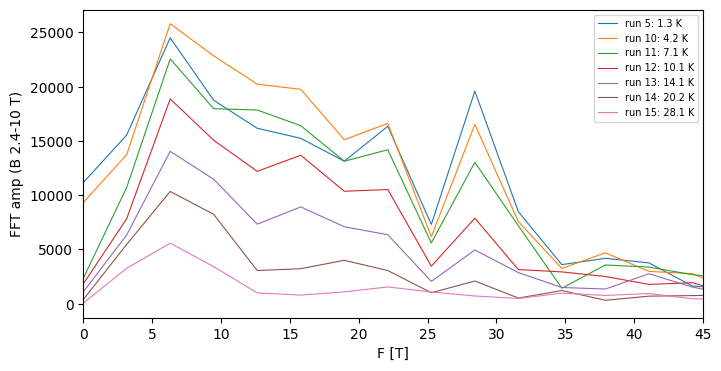

light amp vs T (full window): 1.3K:2.45e+04, 4.2K:2.58e+04, 7.1K:2.26e+04, 10.1K:1.89e+04, 14.1K:1.4e+04, 20.2K:1.03e+04, 28.1K:5.59e+03
heavy amp vs T (full window): 1.3K:1.64e+04, 4.2K:1.66e+04, 7.1K:1.42e+04, 10.1K:1.05e+04, 14.1K:6.36e+03, 20.2K:3.06e+03, 28.1K:1.55e+03
sum   amp vs T (full window): 1.3K:1.96e+04, 4.2K:1.65e+04, 7.1K:1.3e+04, 10.1K:7.88e+03, 14.1K:4.95e+03, 20.2K:2.09e+03, 28.1K:714
light: m* = 0.0388 +- 0.0023 m_e  (windows [(2.4, 4.5), (3.5, 7.0), (2.4, 10.0)], B_eff [3.13 4.67 3.87])
     window (2.4, 4.5) (B_eff 3.13): m* = 0.0316 +- 0.0033
     window (3.5, 7.0) (B_eff 4.67): m* = 0.0494 +- 0.0051
     window (2.4, 10.0) (B_eff 3.87): m* = 0.0342 +- 0.0017
heavy: m* = 0.0479 +- 0.0028 m_e  (windows [(2.4, 4.5), (3.5, 7.0), (2.4, 10.0)], B_eff [3.13 4.67 3.87])
     window (2.4, 4.5) (B_eff 3.13): m* = 0.0486 +- 0.0031
     window (3.5, 7.0) (B_eff 4.67): m* = 0.0478 +- 0.0063
     window (2.4, 10.0) (B_eff 3.87): m* = 0.0477 +- 0.0023
sum  : m* = 0.0645 +- 0.0

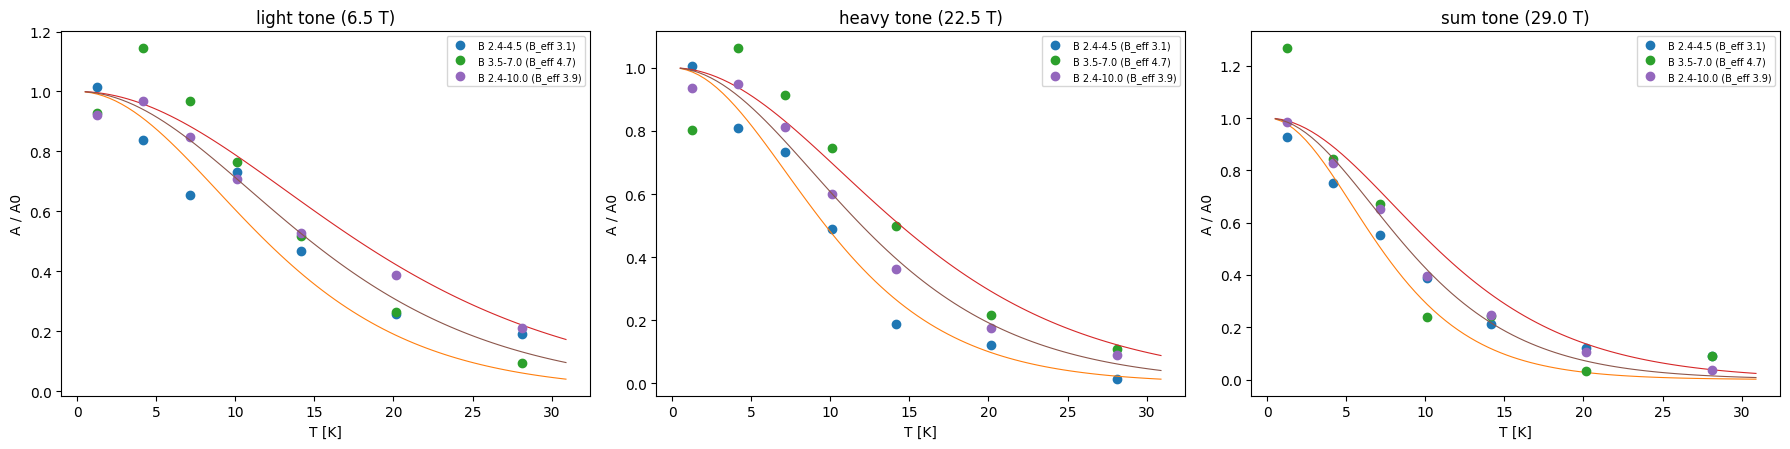

In [11]:
# Runs 10-15 + run 5 — temperature-dependence-vti Flavor B (LK ladder at the electron point). Spectra per rung, tone amplitudes vs T in three 1/B windows, LK fits with per-window B_eff.
"""LK masses with per-tone, per-window B_eff: the window-midpoint B_eff biases tones that live at high B (breakdown
sum) low and low-B tones high. Fit A(T) in several 1/B sub-windows, each with its own B_eff = 1/<1/B>, and fit
m* jointly across windows (the LK factor X/sinh X with X = 14.69 m* T / B_eff_window).
Usage: menv python hera_scratch/lk_ana2.py <run_id> ...   (run 5 first = base rung)
"""
import warnings
import numpy as np
from pathlib import Path
from scipy.optimize import curve_fit
from hera.analysis import open_run, sdh_fft

ids = [5, 10, 11, 12, 13, 14, 15]   # base rung (run 5) + ladder rungs 4..28 K
WINDOWS = [(2.4, 4.5), (3.5, 7.0), (5.5, 10.0), (2.4, 10.0)]
TONES = {"light": (6.5, 2.5), "heavy": (22.5, 3.0), "sum": (29.0, 3.0)}   # centre, half-width [T]

def load(rid):
    r = run(rid); mc = r.meta["measurement_config"]
    B = r.col("magnet_field"); I = r.col("sr0_X") / float(mc["sr0_gain"]); R = r.col("sr1_X") / I; T = r.col("T_sample")
    o = np.argsort(B); return B[o], R[o], T[o]

data = {rid: load(rid) for rid in ids}
Ts = np.array([float(np.nanmean(data[rid][2][(data[rid][0] >= 2.4)])) for rid in ids])
print("T rungs:", np.round(Ts, 2))
amp = {name: np.zeros((len(WINDOWS), len(ids))) for name in TONES}
beff = []
for w, (blo, bhi) in enumerate(WINDOWS):
    beff.append(1.0 / (0.5 * (1 / blo + 1 / bhi)))
    for k, rid in enumerate(ids):
        B, R, T = data[rid]; m = (B >= blo) & (B <= bhi)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            freqs, spec = sdh_fft(R[m][:, None], B[m], b_range=(blo, bhi), bg_degree=3, nfft=4096, log=False)
        sp = spec[0]
        for name, (f0, hw) in TONES.items():
            sel = (freqs > f0 - hw) & (freqs < f0 + hw); amp[name][w, k] = sp[sel].max() if sel.any() else float(np.interp(f0, freqs, sp))
beff = np.array(beff)
dF = [1 / (1 / a - 1 / b) for a, b in WINDOWS]
print("windows:", WINDOWS, "B_eff:", np.round(beff, 2), "dF:", np.round(dF, 1))

def lk_joint_factory(beff_local):
    def lk_joint(x, *p):
        wi = x[0].astype(int); T = x[1]; m = p[0]
        X = 14.69 * m * T / beff_local[wi]
        A0 = np.array([p[1 + i] for i in wi])
        return A0 * X / np.sinh(X)
    return lk_joint

fig0, ax0 = plt.subplots(1, 1, figsize=(8, 4))
for k, rid in enumerate(ids):
    B, R, T = data[rid]; m = (B >= 2.4) & (B <= 10.0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fr, sp = sdh_fft(R[m][:, None], B[m], b_range=(2.4, 10.0), bg_degree=3, nfft=4096, log=False)
    ax0.plot(fr, sp[0], lw=0.8, label=f"run {rid}: {Ts[k]:.1f} K")
ax0.set_xlim(0, 45); ax0.set_xlabel("F [T]"); ax0.set_ylabel("FFT amp (B 2.4-10 T)"); ax0.legend(fontsize=7); plt.show()
for name in TONES:
    print(f"{name:5s} amp vs T (full window): " + ", ".join(f"{Ts[k]:.1f}K:{amp[name][3,k]:.3g}" for k in range(len(ids))))
fig, axs = plt.subplots(1, len(TONES), figsize=(6 * len(TONES), 4.6))
results = {}
for a, (name, (f0, hw)) in zip(axs, TONES.items()):
    use = [w for w in range(len(WINDOWS)) if dF[w] < 2.2 * hw + 3]   # only windows that can still isolate the tone
    xs = np.array([[w, Ts[k]] for w in use for k in range(len(ids))]).T
    ys = np.array([amp[name][w, k] for w in use for k in range(len(ids))])
    p0 = [0.05] + [amp[name][w, 0] for w in use]
    try:
        xloc = np.array([[use.index(int(w)) for w in xs[0]], xs[1]])
        p, cov = curve_fit(lk_joint_factory(beff[use]), xloc, ys, p0=p0, bounds=([0.005] + [0] * len(use), [1.0] + [np.inf] * len(use)))
        err = np.sqrt(np.diag(cov))[0]
        results[name] = (p[0], err, use)
        print(f"{name:5s}: m* = {p[0]:.4f} +- {err:.4f} m_e  (windows {[WINDOWS[w] for w in use]}, B_eff {np.round(beff[use], 2)})")
        for j, w in enumerate(use):
            X = 14.69 * p[0] * Ts / beff[w]
            a.plot(Ts, amp[name][w] / p[1 + j], "o", label=f"B {WINDOWS[w][0]}-{WINDOWS[w][1]} (B_eff {beff[w]:.1f})")
            Tf = np.linspace(0.5, Ts.max() * 1.1, 80); Xf = 14.69 * p[0] * Tf / beff[w]; a.plot(Tf, Xf / np.sinh(Xf), "-", lw=0.8)
    except Exception as ex:
        print(f"{name}: fit failed: {ex}")
    # per-window masses too
    for w in use:
        try:
            pw, cw = curve_fit(lambda T, A0, m: A0 * (14.69 * m * T / beff[w]) / np.sinh(14.69 * m * T / beff[w]), Ts, amp[name][w], p0=(amp[name][w, 0], 0.05), bounds=([0, 0.005], [np.inf, 1]))
            print(f"     window {WINDOWS[w]} (B_eff {beff[w]:.2f}): m* = {pw[1]:.4f} +- {np.sqrt(cw[1,1]):.4f}")
        except Exception as ex:
            print(f"     window {WINDOWS[w]}: {ex}")
    a.set_title(f"{name} tone ({f0} T)"); a.set_xlabel("T [K]"); a.set_ylabel("A / A0"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()


**Read.** Ladder covered (fp'd T_sample): 1.27, 4.15, 7.13, 10.12, 14.14, 20.16, 28.10 K — every rung hover-accepted (spread < 0.1 K over 90 s), intra-sweep T drift ≤ 0.05 K, heater ranges on during rungs (logfile R1/R2 flags), the 28 K rung suppresses the F_L tone to ≈ 0.1 and the light tone to ≈ 0.45 of base — the top rung reaches X ≈ 2.9 (light) / 3.7 (heavy) / 4.3 (F_L tone at the full-window B_eff), so all three amplitudes are on the falling side of X/sinh X (ladder covers the question; the light tone's top is just at the X ≳ 3 design floor).

**LK masses (A(T) = A₀·X/sinh X, X = 14.69·m*·T/B_eff, B_eff = 1/⟨1/B⟩ of the window; joint fit over the 2.4–4.5, 3.5–7 and 2.4–10 T windows):**
- light branch (6.5 T): **m* = 0.039 ± 0.002 m_e** (per window 0.032 / 0.049 / 0.034);
- heavy branch (22.5 T): **m* = 0.048 ± 0.003 m_e** (0.049 / 0.048 / 0.048 — window-stable);
- F_L tone (29 T): **0.065 ± 0.004 m_e joint, but window-dependent: 0.051 ± 0.003 (2.4–4.5 T) vs 0.100 ± 0.010 (3.5–7 T)** — a fork (STYLE rule 14), not refined further: in the low window the 29 T peak is within δF = 5 T of the 22.5 T fundamental (contaminated), in the mid window it is isolated and reads 0.10 ≈ m_light + m_heavy = 0.087 — the additive mass of an orbit traversing both pockets (breakdown), not the ABCA pocket's 0.076 with no partner.

**Verify items closed here:** (a) *beat exclusion* — the coexisting light component is **lighter** than the heavy branch (0.039 < 0.048, 2.4σ): a genuine second band, not a beat of the heavy tone (decisive rule); (b) *F_L-tone origin* — mass above both fundamentals and rising with B-window, consistent with inter-block breakdown; (c) *mass ratio* — heavy/light = 1.23 ± 0.10 vs the ABAB model's ≈ 2.2 at n ≈ 2.8 (φ² = 2.6 limit): **not the φ²-split**; the light-tone amplitude comes from a 2-period record and a ±2.5 T FFT window, so its LK is the softest number of the session, and the model masses are semi-quantitative — recorded as a hedge on the ABAB call, not as a counter-template (no alternative template predicts light ≈ 0.04 + heavy ≈ 0.05 + sum ≈ 0.1 with a 0.22/0.78 Luttinger partition: trilayer ML would be ≈ 0.015, ABCB's Dirac partner lighter still).


## Session call — vti-02 stacking (investigation `tetralayer-stacking-fs-count`, output contract)

**1. Per-region verdict.** Channel/pair **sr1 = B_1–B_2 (source T_0, drain B_3): ABAB (Bernal) — strong.** No other R_xx pair is wired this cooldown (sr2/sr3 n.c.), so this is a one-region call; the flake may host other domains elsewhere.

**2. Evidence (all at D ≈ 0, electron side, Si = 0, T_e ≈ 8 K per rig card; global density scale 0.93 ± 0.03 pinned on the whole peak set by the Luttinger sum — design densities ×0.93):**
- Run 5 (spot, n ≈ 2.8): fundamentals **f₁ = 6.2 T, f₂ = 21.8 T**, sum **28.1 T** (= F_L at scale 0.90), difference **15.6 T**; onset 2.4 T; partition 0.78/0.22. Ana cells 16–18.
- Run 8 (fan, n 1.35–3.06 actual, 36 rows × 41 columns, δF 3.1 T): light branch 3.2 → 6.9 T at 0.21–0.22·F_L across the range, on the ABAB light curve (slope ≈ 3.3 T/10¹²; trilayer ML would be ≈ 1); heavy branch 20.8 → 25.2 T ≈ 0.77·F_L on the ABAB heavy curve for n ≳ 2.5 (unresolvable from the F_L tone below); a tone at F_L in every column. Luttinger: f₁ + f₂ = 32.1 vs 33.1 T (n = 3.06), 28.0 vs 28.1 (run 5). Ana cells 22–25 (Onsager overlays with the model curves in cell 23).
- F_L-tone origin: B-window split — sum/heavy 0.26 → 0.70 → 1.15 from low to high windows (run 5), 0.99 → 2.11 (fan column n = 3.16): strengthens with B like a breakdown / intermodulation orbit (cell 24); grid-change (uniform-B vs uniform-1/B) reproduces the set; LK: the F_L tone's mass 0.065 ± 0.004 (joint; 0.051 in 2.4–4.5 T, 0.100 in 3.5–7 T) m_e exceeds both fundamentals (0.039 ± 0.002 light, 0.048 ± 0.003 heavy) and is window-dependent (0.05 low-B → 0.10 mid-B) — consistent with the additive breakdown-orbit mass (≈ 0.085) within the window fork, not with a single pocket of fixed mass. Beat exclusion: the light branch is **lighter** than the heavy one → a genuine second band, not a beat (decisive per the investigation's rule). Ana cells 26–27.
- Degeneracy audit: one global scale (0.93), no 2×/4× multiplicity → g = 4 holds; ν ≈ 16-family rays visible in the raw fan.

**3. Confidence and hedges.** Strong, not decisive: (i) **one contact pair** — mosaic caveat, no cross-region check possible this cooldown; (ii) **mass ratio** — measured heavy/light ≈ 1.2–1.4 vs the model's ≈ 2.2 at this density (φ² limit 2.6): the light tone's LK rests on a 2-period record (6 T in a 0.32 T⁻¹ span) and is the least trustworthy number here; the model masses are semi-quantitative (README). The frequencies/partition/Luttinger/breakdown behaviour carry the call, the masses support "two genuine bands" without confirming the φ² split; (iii) **δF = 3.1 T** — the heavy branch is resolved from the F_L tone only for n ≳ 2.5; the B-window split is a weak null below n ≈ 2.7; (iv) **hole side unmeasured**: the D = 0 line reaches only −1.1 × 10¹² (TG limit) and a V_bg-independent series segment (CNP at V_tg ≈ −0.2 V, Si-insensitive, runs 4/6/7) is driven to neutrality there — geometry-limited on this pair, not a null; (v) **series-segment tone**: its predicted V_tg-only line (12–20 T) is not identified as any branch (the 13–16 T peaks track f₂ − f₁), but cannot be excluded at δF = 3 T; (vi) **absolute layer number**: the peak set matches the 4L ABAB overlay, not the trilayer ML+BL family (light fraction 0.21 vs 0.12–0.15; heavy 0.77 vs 0.87) — N = 4 is what the transport supports; pentalayer not tested; (vii) ABCA: excluded as the sole stacking of this region (a 0.21·F_L branch has no ABCA parent; sub-F_L fundamentals dominate); an ABCA minority domain contributing to the F_L tone is not excluded (mixed-domain confound of the sum tone); ABCB: not supported (light branch linear at 0.21·F_L, no Dirac-like supra-linear shape resolvable; citation-grade template).

**4. What would firm it.** A second R_xx pair on the flake (region cross-check) — operator rewiring; a cleaner R_xx pair without Hall admixture for the QH-ray lever-arm pin and ν = 8/12/16 ladder; a longer 1/B record for the light tone (lower onset: higher mobility cooldown, or mK/lower T_e rig) for the φ² mass split; the hole side at D ≈ 0 on a pair whose path is fully dual-gated; a second-density LK rung set.

**5. Calibration and housekeeping for the card.** c_bg/c_tg = 0.727 (run 4, ratio data-calibrated); absolute scale 0.93 ± 0.03 of the geometry prior (Luttinger, runs 5/8) — i.e. c_tg ≈ 2.60 × 10⁻³ F/m² (≈ 10.2 nm hBN-equivalent) with c_bg ≈ 1.89 × 10⁻³; n_offset −0.07 × 10¹² (design frame); D_offset 0 (gap minimum at geometric D = +0.006 V/nm); CNP ridge gaps to 3 kΩ at D = +0.3 V/nm; series segment CNP at V_tg ≈ −0.2 V (Si-insensitive); SdH onset 2.4 T at n ≈ 2.8 × 10¹² electrons; Hall admixture α ≈ 0.2 on B_1–B_2.
